In [3]:
import os
import zipfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import random

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, models
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.callbacks import EarlyStopping

from sklearn.metrics import confusion_matrix
from sklearn.metrics import classification_report, ConfusionMatrixDisplay

print("TensorFlow version:", tf.__version__)
print("GPU available:", tf.config.list_physical_devices('GPU'))

TensorFlow version: 2.21.0
GPU available: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [4]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [5]:
import os

data_dir = '/content/drive/MyDrive/animals'

print(os.listdir(data_dir))
print("Cat images:", len(os.listdir(data_dir + '/cat')))
print("Dog images:", len(os.listdir(data_dir + '/dog')))

['cat', 'dog']
Cat images: 501
Dog images: 500


In [24]:
import tensorflow as tf
from tensorflow.keras.preprocessing.image import ImageDataGenerator

IMG_SIZE = (150, 150)
BATCH_SIZE = 32
SEED = 42

data_gen = ImageDataGenerator(
    rescale=1./255,
    validation_split=0.2
)

train_data = data_gen.flow_from_directory(
    data_dir,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='binary',
    subset='training',
    seed=SEED
)

val_data = data_gen.flow_from_directory(
    data_dir,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='binary',
    subset='validation',
    seed=SEED,
    shuffle=False
)

print("Class labels:", train_data.class_indices)

Found 801 images belonging to 2 classes.
Found 200 images belonging to 2 classes.
Class labels: {'cat': 0, 'dog': 1}


In [27]:
print("Class labels:", train_data.class_indices)

print("Training images:", train_data.samples)
print("Validation images:", val_data.samples)

Class labels: {'cat': 0, 'dog': 1}
Training images: 801
Validation images: 200


In [28]:
from tensorflow.keras import layers, models

model = models.Sequential([
    layers.Input(shape=(150, 150, 3)),

    layers.Conv2D(32, (3, 3), activation='relu'),
    layers.MaxPooling2D(2, 2),

    layers.Conv2D(64, (3, 3), activation='relu'),
    layers.MaxPooling2D(2, 2),

    layers.Conv2D(128, (3, 3), activation='relu'),
    layers.MaxPooling2D(2, 2),

    layers.Flatten(),

    layers.Dense(128, activation='relu'),
    layers.Dropout(0.5),

    layers.Dense(1, activation='sigmoid')
])

model.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_6 (Conv2D)               │ (None, 148, 148, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_6 (MaxPooling2D)  │ (None, 74, 74, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_7 (Conv2D)               │ (None, 72, 72, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_7 (MaxPooling2D)  │ (None, 36, 36, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_8 (Conv2D)               │ (None, 34, 34, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_8 (MaxPooling2D)  │ (None, 17, 17, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_2 (Flatten)             │ (None, 36992)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 128)            │     4,735,104 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,828,481 (18.42 MB)

 Trainable params: 4,828,481 (18.42 MB)

 Non-trainable params: 0 (0.00 B)

In [29]:
model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

In [30]:
history = model.fit(
    train_data,
    validation_data=val_data,
    epochs=5,
    verbose=1
)

Epoch 1/5
26/26 ━━━━━━━━━━━━━━━━━━━━ 22s 697ms/step - accuracy: 0.6105 - loss: 0.6514 - val_accuracy: 0.8050 - val_loss: 0.5224
Epoch 2/5
26/26 ━━━━━━━━━━━━━━━━━━━━ 16s 633ms/step - accuracy: 0.8002 - loss: 0.4478 - val_accuracy: 0.8650 - val_loss: 0.3475
Epoch 3/5
26/26 ━━━━━━━━━━━━━━━━━━━━ 16s 606ms/step - accuracy: 0.8964 - loss: 0.2811 - val_accuracy: 0.9000 - val_loss: 0.2492
Epoch 4/5
26/26 ━━━━━━━━━━━━━━━━━━━━ 16s 629ms/step - accuracy: 0.9413 - loss: 0.1803 - val_accuracy: 0.9250 - val_loss: 0.1628
Epoch 5/5
26/26 ━━━━━━━━━━━━━━━━━━━━ 16s 605ms/step - accuracy: 0.9588 - loss: 0.1382 - val_accuracy: 0.9050 - val_loss: 0.2415


In [31]:
loss, accuracy = model.evaluate(val_data)

print("Validation Loss:", loss)
print("Validation Accuracy:", accuracy * 100, "%")

7/7 ━━━━━━━━━━━━━━━━━━━━ 3s 448ms/step - accuracy: 0.9050 - loss: 0.2415
Validation Loss: 0.24148942530155182
Validation Accuracy: 90.49999713897705 %


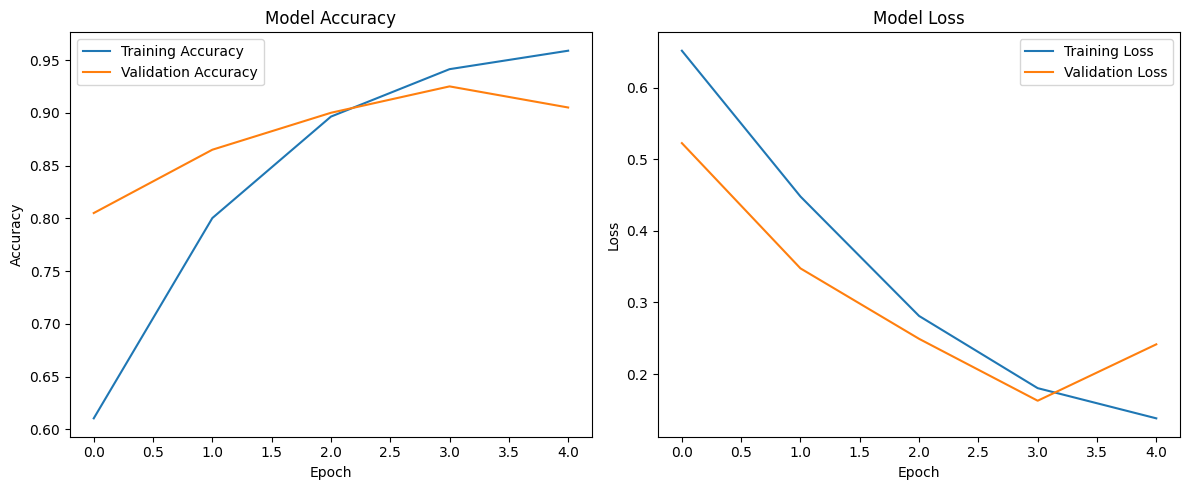

In [32]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title('Model Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('Model Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()

plt.tight_layout()
plt.show()

In [33]:
from google.colab import files

uploaded = files.upload()

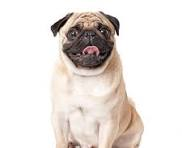

Prediction: Dog 🐶
Confidence: 99.51%


In [15]:
import numpy as np
from tensorflow.keras.utils import load_img, img_to_array
from IPython.display import display, Image
import os

img_path = list(uploaded.keys())[0]

img = load_img(img_path, target_size=(150, 150))
img_array = img_to_array(img) / 255.0
img_array = np.expand_dims(img_array, axis=0)

prediction = model.predict(img_array, verbose=0)[0][0]

display(Image(filename=img_path))

if prediction >= 0.5:
    print("Prediction: Dog 🐶")
    print(f"Confidence: {prediction * 100:.2f}%")
else:
    print("Prediction: Cat 🐱")
    print(f"Confidence: {(1 - prediction) * 100:.2f}%")

In [16]:
from google.colab import files

uploaded = files.upload()

Saving cat.jpg to cat.jpg


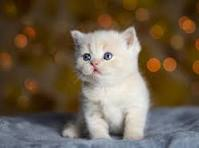

Prediction: Cat 🐱
Confidence: 99.72%


In [17]:
import numpy as np
from tensorflow.keras.utils import load_img, img_to_array
from IPython.display import display, Image
import os

img_path = list(uploaded.keys())[0]

img = load_img(img_path, target_size=(150, 150))
img_array = img_to_array(img) / 255.0
img_array = np.expand_dims(img_array, axis=0)

prediction = model.predict(img_array, verbose=0)[0][0]

display(Image(filename=img_path))

if prediction >= 0.5:
    print("Prediction: Dog 🐶")
    print(f"Confidence: {prediction * 100:.2f}%")
else:
    print("Prediction: Cat 🐱")
    print(f"Confidence: {(1 - prediction) * 100:.2f}%")

7/7 ━━━━━━━━━━━━━━━━━━━━ 3s 434ms/step


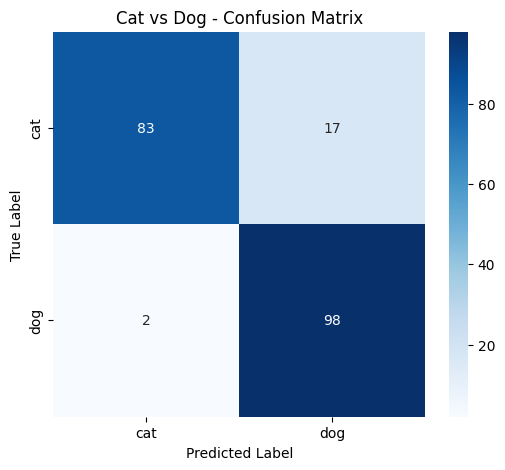

              precision    recall  f1-score   support

         cat     0.9765    0.8300    0.8973       100
         dog     0.8522    0.9800    0.9116       100

    accuracy                         0.9050       200
   macro avg     0.9143    0.9050    0.9045       200
weighted avg     0.9143    0.9050    0.9045       200



In [35]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import confusion_matrix, classification_report

# True labels
y_true = val_data.classes

# Predicted probabilities
val_data.reset()
y_prob = model.predict(val_data, verbose=1).ravel()

# Convert probabilities to class labels
y_pred = (y_prob >= 0.5).astype(int)

# Class names
class_names = list(val_data.class_indices.keys())

# Confusion matrix
cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(6, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=class_names,
    yticklabels=class_names
)

plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.title('Cat vs Dog - Confusion Matrix')
plt.show()

print(classification_report(
    y_true,
    y_pred,
    target_names=class_names,
    digits=4
))

7/7 ━━━━━━━━━━━━━━━━━━━━ 3s 431ms/step
Prediction Accuracy: 90.5 %

Classification Report:
              precision    recall  f1-score   support

         Cat       0.98      0.83      0.90       100
         Dog       0.85      0.98      0.91       100

    accuracy                           0.91       200
   macro avg       0.91      0.91      0.90       200
weighted avg       0.91      0.91      0.90       200



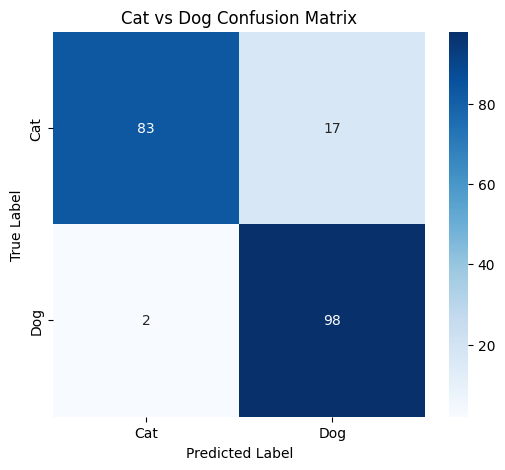

In [36]:
import numpy as np
from sklearn.metrics import confusion_matrix, classification_report
import seaborn as sns
import matplotlib.pyplot as plt

val_data.reset()

y_prob = model.predict(val_data, verbose=1).ravel()
y_pred = (y_prob >= 0.5).astype(int)
y_true = val_data.classes

print("Prediction Accuracy:",
      round(np.mean(y_true == y_pred) * 100, 2), "%")

print("\nClassification Report:")
print(classification_report(
    y_true, y_pred,
    target_names=['Cat', 'Dog']
))

cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(6, 5))
sns.heatmap(
    cm, annot=True, fmt='d', cmap='Blues',
    xticklabels=['Cat', 'Dog'],
    yticklabels=['Cat', 'Dog']
)
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.title('Cat vs Dog Confusion Matrix')
plt.show()

In [37]:
model.save('/content/drive/MyDrive/cat_dog_model.keras')

print("Model saved successfully!")

Model saved successfully!
